In [1]:
import geopandas as gpd
import pandas as pd
from pathlib import Path

In [2]:
RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")
list(RAW.iterdir())

[PosixPath('../data/raw/Agregados_por_setores_renda_responsavel_BR.csv'),
 PosixPath('../data/raw/GO_setores_CD2022.gpkg'),
 PosixPath('../data/raw/.gitkeep')]

In [3]:
sectors = gpd.read_file(RAW / "GO_setores_CD2022.gpkg")
sectors.shape

(12861, 30)

In [4]:
sectors.columns

Index(['CD_SETOR', 'SITUACAO', 'CD_SIT', 'CD_TIPO', 'AREA_KM2', 'CD_REGIAO',
       'NM_REGIAO', 'CD_UF', 'NM_UF', 'CD_MUN', 'NM_MUN', 'CD_DIST', 'NM_DIST',
       'CD_SUBDIST', 'NM_SUBDIST', 'CD_BAIRRO', 'NM_BAIRRO', 'CD_NU', 'NM_NU',
       'CD_FCU', 'NM_FCU', 'CD_AGLOM', 'NM_AGLOM', 'CD_RGINT', 'NM_RGINT',
       'CD_RGI', 'NM_RGI', 'CD_CONCURB', 'NM_CONCURB', 'geometry'],
      dtype='str')

In [5]:
sectors.head()

,CD_SETOR,SITUACAO,CD_SIT,CD_TIPO,AREA_KM2,CD_REGIAO,NM_REGIAO,CD_UF,NM_UF,CD_MUN,...,NM_FCU,CD_AGLOM,NM_AGLOM,CD_RGINT,NM_RGINT,CD_RGI,NM_RGI,CD_CONCURB,NM_CONCURB,geometry
0,520005005000001,Urbana,1,0,0.153902,5,Centro-Oeste,52,Goiás,5200050,...,NaN,NaN,NaN,5201,Goiânia,520001,Goiânia,5208707,Goiânia/GO,"POLYGON ((-49.43793 -16.75877, -49.43848 -16.7..."
1,520005005000002,Urbana,1,0,0.314781,5,Centro-Oeste,52,Goiás,5200050,...,NaN,NaN,NaN,5201,Goiânia,520001,Goiânia,5208707,Goiânia/GO,"POLYGON ((-49.43754 -16.75932, -49.43793 -16.7..."
2,520005005000003,Urbana,1,0,0.201200,5,Centro-Oeste,52,Goiás,5200050,...,NaN,NaN,NaN,5201,Goiânia,520001,Goiânia,5208707,Goiânia/GO,"POLYGON ((-49.43525 -16.76401, -49.43526 -16.7..."
3,520005005000004,Urbana,1,0,0.204826,5,Centro-Oeste,52,Goiás,5200050,...,NaN,NaN,NaN,5201,Goiânia,520001,Goiânia,5208707,Goiânia/GO,"POLYGON ((-49.42468 -16.76712, -49.42479 -16.7..."
4,520005005000005,Rural,8,0,31.387504,5,Centro-Oeste,52,Goiás,5200050,...,NaN,NaN,NaN,5201,Goiânia,520001,Goiânia,5208707,Goiânia/GO,"POLYGON ((-49.43754 -16.86015, -49.43849 -16.8..."


In [6]:
sectors.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 12861 entries, 0 to 12860
Data columns (total 30 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   CD_SETOR    12861 non-null  str     
 1   SITUACAO    12859 non-null  str     
 2   CD_SIT      12861 non-null  str     
 3   CD_TIPO     12861 non-null  str     
 4   AREA_KM2    12861 non-null  float64 
 5   CD_REGIAO   12861 non-null  str     
 6   NM_REGIAO   12861 non-null  str     
 7   CD_UF       12861 non-null  str     
 8   NM_UF       12861 non-null  str     
 9   CD_MUN      12861 non-null  str     
 10  NM_MUN      12861 non-null  str     
 11  CD_DIST     12861 non-null  str     
 12  NM_DIST     12861 non-null  str     
 13  CD_SUBDIST  12861 non-null  str     
 14  NM_SUBDIST  2302 non-null   str     
 15  CD_BAIRRO   85 non-null     str     
 16  NM_BAIRRO   85 non-null     str     
 17  CD_NU       255 non-null    str     
 18  NM_NU       255 non-null    str     
 

In [7]:
sectors.crs

<Geographic 2D CRS: EPSG:4674>
Name: SIRGAS 2000
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: Latin America - Central America and South America - onshore and offshore. Brazil - onshore and offshore.
- bounds: (-122.19, -59.87, -25.28, 32.72)
Datum: Sistema de Referencia Geocentrico para las AmericaS 2000
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [8]:
sectors["CD_MUN"].head()

0    5200050
1    5200050
2    5200050
3    5200050
4    5200050
Name: CD_MUN, dtype: str

In [9]:
goiania_sectors = sectors[sectors["CD_MUN"] == "5208707"].copy()
goiania_sectors.shape

(2310, 30)

In [10]:
goiania_sectors["NM_MUN"].unique()

<StringArray>
['Goiânia']
Length: 1, dtype: str

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

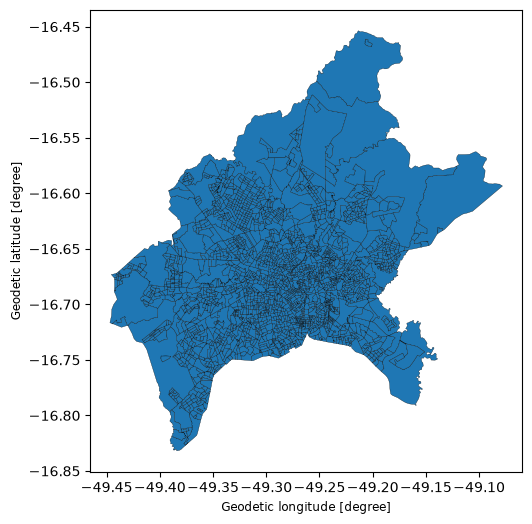

In [11]:
goiania_sectors.plot(figsize=(6, 6), edgecolor="black", linewidth=0.2)

In [12]:
goiania_sectors["SITUACAO"].value_counts()

SITUACAO
Urbana    2291
Rural       19
Name: count, dtype: int64

In [13]:
goiania_sectors["CD_TIPO"].value_counts()

CD_TIPO
0    2199
1      86
4      15
7       5
3       3
6       1
2       1
Name: count, dtype: int64

In [14]:
goiania_sectors["AREA_KM2"].describe()

count    2310.000000
mean        0.315713
std         1.949129
min         0.000846
25%         0.060883
50%         0.106466
75%         0.180868
max        46.986975
Name: AREA_KM2, dtype: float64

In [15]:
goiania_sectors.nlargest(5, "AREA_KM2")[["CD_SETOR", "SITUACAO", "AREA_KM2"]]

,CD_SETOR,SITUACAO,AREA_KM2
6624,520870705630134,Rural,46.986975
6618,520870705630128,Rural,37.444661
6630,520870715000002,Rural,36.793405
6635,520870715000008,Rural,30.710308
6626,520870705630136,Rural,27.650357


In [16]:
goiania_sectors.nsmallest(5, "AREA_KM2")[["CD_SETOR", "SITUACAO", "AREA_KM2"]]

,CD_SETOR,SITUACAO,AREA_KM2
5097,520870705200050,Urbana,0.000846
4610,520870705090050,Urbana,0.001693
4367,520870705010041,Urbana,0.002813
4761,520870705130065,Urbana,0.003174
4790,520870705130094,Urbana,0.003511


#### Os maiores setores são rurais. Necessidade de decidir o que fazer com os rurais
#### Os menores são urbanos e minúsculos. 

In [17]:
one_pixel = 0.0009   # 30 m x 30 m, em km²
thermal_pixel = 0.01 # 100 m x 100 m, em km²

(goiania_sectors["AREA_KM2"] < one_pixel).sum()

np.int64(1)

In [18]:
(goiania_sectors["AREA_KM2"] < thermal_pixel).sum()

np.int64(49)

In [19]:
# Marcando os setores rurais  (análise principal roda só nos urbanos)
goiania_sectors["is_rural"] = goiania_sectors["SITUACAO"] == "Rural"

In [20]:
goiania_sectors["small_sector"] = goiania_sectors["AREA_KM2"] < thermal_pixel

In [21]:
goiania_sectors.to_file(PROCESSED / "goiania_sectors.gpkg", driver="GPKG")

### Part II - Income

In [22]:
income = pd.read_csv(RAW / "Agregados_por_setores_renda_responsavel_BR.csv", sep=";", dtype={"CD_SETOR": str},)
income.shape

(458772, 7)

In [23]:
income.columns.tolist()

['CD_SETOR', 'V06001', 'V06002', 'V06003', 'V06004', 'V06005', 'V06006']

In [24]:
income.head()

,CD_SETOR,V06001,V06002,V06003,V06004,V06005,V06006
0,110001505000002,336,928,1.67,2453.03,13047638.93,1212
1,110001505000003,208,556,1.79,2126.44,2348222.39,1500
2,110001505000004,85,222,1.6,1664.94,1270082.06,1200
3,110001505000006,281,783,2.41,1722.4,1446560.6,1200
4,110001505000007,291,748,1.38,1930.94,2255368.87,1212


In [25]:
income["CD_SETOR"].str.len().value_counts()

CD_SETOR
15    458772
Name: count, dtype: int64

In [26]:
goiania_income = income[income["CD_SETOR"].str.startswith("5208707")].copy()
goiania_income.shape

(2304, 7)

In [27]:
goiania_income.dtypes

CD_SETOR    str
V06001      str
V06002      str
V06003      str
V06004      str
V06005      str
V06006      str
dtype: object

In [28]:
cols = ["V06001", "V06002", "V06003", "V06004", "V06005", "V06006"]

for col in cols:
    bad = goiania_income.loc[pd.to_numeric(goiania_income[col], errors="coerce").isna(), col]
    print(col, bad.value_counts(dropna=False).to_dict())

V06001 {'X': 15}
V06002 {'X': 15}
V06003 {'X': 15}
V06004 {'X': 15}
V06005 {'X': 15}
V06006 {'X': 15}


In [29]:
goiania_income[cols] = goiania_income[cols].apply(pd.to_numeric, errors="coerce")
goiania_income.dtypes

CD_SETOR        str
V06001      float64
V06002      float64
V06003      float64
V06004      float64
V06005      float64
V06006      float64
dtype: object

In [30]:
goiania_income[["V06004", "V06006"]].isna().sum()

V06004    15
V06006    15
dtype: int64

In [ ]:
sector_ids_mesh = set(goiania_sectors["CD_SETOR"])
sector_ids_income = set(goiania_income["CD_SETOR"])

print(len(sector_ids_mesh - sector_ids_income))  
print(len(sector_ids_income - sector_ids_mesh))   

6
0


In [32]:
goiania_income[cols].isna().all(axis=1).sum()

np.int64(15)

In [33]:
missing_ids = (sector_ids_mesh - sector_ids_income) | set(
    goiania_income.loc[goiania_income["V06006"].isna(), "CD_SETOR"]
)
len(missing_ids)

21

In [34]:
goiania_sectors[goiania_sectors["CD_SETOR"].isin(missing_ids)][
    ["CD_SETOR", "SITUACAO", "CD_TIPO", "AREA_KM2", "NM_BAIRRO"]
]

,CD_SETOR,SITUACAO,CD_TIPO,AREA_KM2,NM_BAIRRO
4553,520870705080044,Urbana,4,0.158982,NaN
4563,520870705080054,Urbana,3,0.012476,NaN
4610,520870705090050,Urbana,7,0.001693,NaN
4643,520870705110003,Urbana,4,0.440319,NaN
4649,520870705110010,Urbana,4,0.048367,NaN
4790,520870705130094,Urbana,7,0.003511,NaN
4840,520870705150036,Urbana,4,0.082791,NaN
5097,520870705200050,Urbana,3,0.000846,NaN
5225,520870705250012,Urbana,4,0.219131,NaN
5351,520870705290008,Urbana,7,0.026286,NaN


In [35]:
merged = goiania_sectors.merge(goiania_income, on="CD_SETOR", how="left", indicator=True)
merged["_merge"].value_counts()

_merge
both          2304
left_only        6
right_only       0
Name: count, dtype: int64

In [36]:
merged["has_income"] = merged["V06006"].notna()
merged["has_income"].sum()

np.int64(2289)

In [37]:
goiania_sectors["NM_BAIRRO"].isna().sum()

np.int64(2310)

In [38]:
merged.loc[merged["has_income"], "V06006"].describe()

count     2289.000000
mean      3345.266273
std       3066.924882
min       1000.000000
25%       1600.000000
50%       2100.000000
75%       3550.000000
max      25000.000000
Name: V06006, dtype: float64

In [39]:
cols_names = ["CD_BAIRRO", "NM_BAIRRO", "NM_SUBDIST", "NM_DIST", "NM_NU", "NM_CONCURB"]
goiania_sectors[cols_names].isna().sum()

CD_BAIRRO     2310
NM_BAIRRO     2310
NM_SUBDIST       8
NM_DIST          0
NM_NU         2305
NM_CONCURB       0
dtype: int64

In [40]:
goiania_sectors[["NM_DIST", "NM_SUBDIST", "NM_CONCURB"]].nunique()

NM_DIST        2
NM_SUBDIST    63
NM_CONCURB     1
dtype: int64

In [41]:
goiania_sectors["NM_DIST"].value_counts()

NM_DIST
Goiânia      2302
Vila Rica       8
Name: count, dtype: int64

In [42]:
goiania_sectors["NM_SUBDIST"].value_counts().head(15)

NM_SUBDIST
U.T.P. Zona Rural                                     115
U.T.P. Finsocial                                      103
U.T.P. Bueno                                           87
U.T.P. Celina Park/Recreio dos Funcionários            78
U.T.P. Jardim Novo Mundo                               68
U.T.P. Parque das Laranjeiras e Jardim da Luz          66
U.T.P. Parque Amazônia                                 60
U.T.P. Pedro Ludovico/Bela Vista/Jardins das Esmer     59
U.T.P. Jardim América                                  59
U.T.P. Cidade Jardim                                   59
U.T.P. Mutirão e Curitiba                              56
U.T.P. Oeste                                           55
U.T.P. Baliza-Itaipu                                   53
U.T.P. Jardim Europa                                   51
U.T.P. Novo Horizonte/Faiçalville                      51
Name: count, dtype: int64

In [43]:
goiania_sectors.loc[goiania_sectors["NM_SUBDIST"].isna(), ["CD_SETOR", "NM_DIST", "SITUACAO"]]

,CD_SETOR,NM_DIST,SITUACAO
6629,520870715000001,Vila Rica,Urbana
6630,520870715000002,Vila Rica,Rural
6631,520870715000003,Vila Rica,Rural
6632,520870715000004,Vila Rica,Urbana
6633,520870715000005,Vila Rica,Rural
6634,520870715000006,Vila Rica,Urbana
6635,520870715000008,Vila Rica,Rural
6636,520870715000009,Vila Rica,Urbana


In [44]:
zr = goiania_sectors[goiania_sectors["NM_SUBDIST"] == "U.T.P. Zona Rural"]
zr["SITUACAO"].value_counts()
zr["AREA_KM2"].describe()

count    115.000000
mean       2.163811
std        6.915008
min        0.021630
25%        0.109792
50%        0.188718
75%        0.742489
max       46.986975
Name: AREA_KM2, dtype: float64

In [45]:
zr["SITUACAO"].value_counts()

SITUACAO
Urbana    104
Rural      11
Name: count, dtype: int64

In [47]:
merged["in_rural_zone"] = merged["NM_SUBDIST"] == "U.T.P. Zona Rural"
merged["in_rural_zone"].sum() 

np.int64(115)

In [48]:
valid = merged.loc[merged["has_income"], "V06006"]
valid.quantile([0.2, 0.4, 0.6, 0.8])

0.2    1500.0
0.4    2000.0
0.6    2500.0
0.8    4348.8
Name: V06006, dtype: float64

In [49]:
valid.value_counts().head(8)

V06006
2000.0    328
1212.0    173
1500.0    166
3000.0    140
2500.0    131
1800.0    107
5000.0     96
4000.0     83
Name: count, dtype: int64

In [50]:
merged["income_quintile"] = pd.qcut(
    merged.loc[merged["has_income"], "V06006"], 5, labels=[1, 2, 3, 4, 5]
)
merged["income_quintile"].value_counts().sort_index()

income_quintile
1    500
2    602
3    335
4    394
5    458
Name: count, dtype: int64

In [51]:
(merged.groupby("income_quintile", observed=True)["V06006"]
       .agg(["min", "max", "count"]))

,min,max,count
income_quintile,,,
1,1000.0,1500.0,500
2,1504.0,2000.0,602
3,2000.5,2500.0,335
4,2550.0,4348.0,394
5,4350.0,25000.0,458


In [52]:
merged["income_quintile"] = merged["income_quintile"].astype("Int64")

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

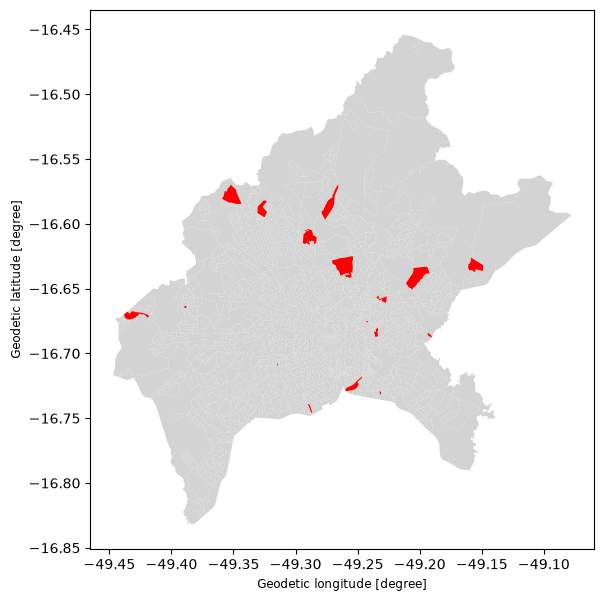

In [53]:
ax = merged.plot(color="lightgrey", figsize=(7, 7))
merged[~merged["has_income"]].plot(ax=ax, color="red")

In [54]:
goiania_sectors["NM_FCU"].notna().sum()

np.int64(86)

In [55]:
zr = merged[merged["NM_SUBDIST"] == "U.T.P. Zona Rural"]
zr["CD_SIT"].value_counts()

CD_SIT
1    87
2    15
8    11
3     2
Name: count, dtype: int64

In [56]:
merged["in_rural_zone"] = merged["NM_SUBDIST"] == "U.T.P. Zona Rural"
merged["income_quintile"] = merged["income_quintile"].astype("Int64")

merged = merged.rename(columns={
    "CD_SETOR": "sector_id", "CD_TIPO": "sector_type", "AREA_KM2": "area_km2",
    "NM_SUBDIST": "subdistrict", "NM_FCU": "favela_name",
    "V06001": "n_households", "V06002": "n_residents", "V06003": "residents_variance",
    "V06004": "income_mean", "V06005": "income_variance", "V06006": "income_median",
})

keep = ["sector_id", "sector_type", "area_km2", "subdistrict", "favela_name",
        "n_households", "n_residents", "income_mean", "income_median",
        "income_quintile", "has_income", "is_rural", "small_sector", "in_rural_zone"]

final = merged[keep + ["geometry"]].copy()
final.to_file(PROCESSED / "sectors_income.gpkg", driver="GPKG")
final.drop(columns="geometry").to_csv(PROCESSED / "sectors_income.csv", index=False)

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

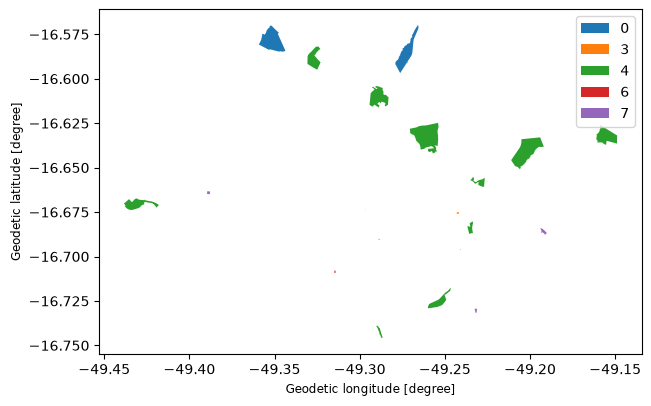

In [58]:
merged[~merged["has_income"]].plot(column="sector_type", categorical=True, legend=True, figsize=(7, 7))

In [59]:
merged = merged.rename(columns={"CD_SIT": "situation_code"})

final = merged[keep + ["situation_code", "geometry"]].copy()
final.to_file(PROCESSED / "sectors_income.gpkg", driver="GPKG")
final.drop(columns="geometry").to_csv(PROCESSED / "sectors_income.csv", index=False)

In [60]:
check = gpd.read_file(PROCESSED / "sectors_income.gpkg")
check.shape   # (2310, 16)

(2310, 16)